# Посмотрим на данные

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Lorenz_generate import Lorenz

dt = 0.1
steps = 100000

x, y, z = Lorenz().generate(dt=dt, steps=steps)
time = np.arange(len(x)) * dt

In [2]:
print("Количество наблюдений:", len(x))
print("Первые 10 значений:", x[:10])
print("Минимум:", x.min())
print("Максимум:", x.max())
print("Среднее:", x.mean())
print("Стандартное отклонение:", x.std())

Количество наблюдений: 100001
Первые 10 значений: [  1.           2.23690694   6.54205728  16.67964382  12.72318152
   0.9517379   -4.0292296   -6.15254078  -8.27956828 -10.22673302]
Минимум: -18.87080236374363
Максимум: 18.134929327874133
Среднее: 0.19649317175042808
Стандартное отклонение: 7.796220474656231


Посмотрим на первые 500 наблюдений

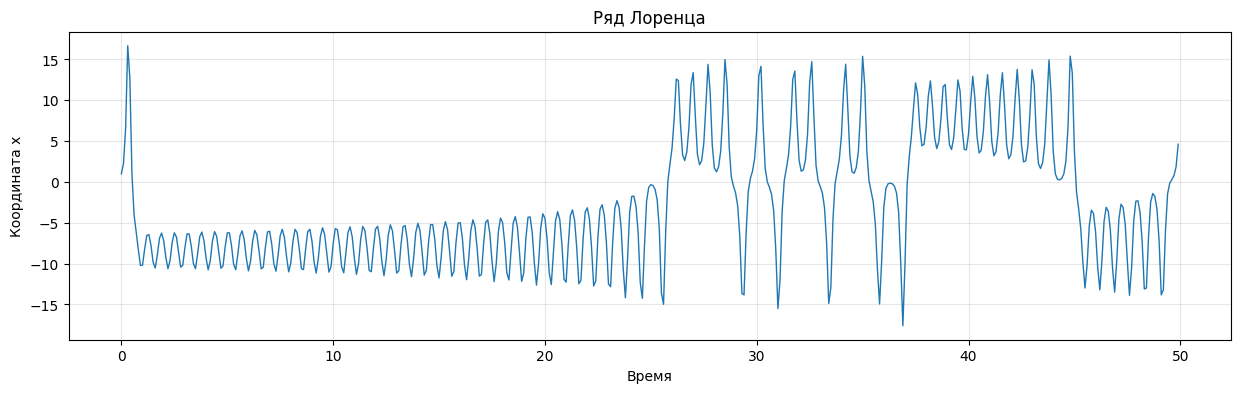

In [68]:

plt.figure(figsize=(15, 4))
plt.plot(time[:500], x[:500], linewidth=1)

plt.xlabel("Время")
plt.ylabel("Координата x")
plt.title("Ряд Лоренца")
plt.grid(alpha=0.3)

plt.show()

# Подготовка данных

Отбрасываю начало

In [4]:
burn_in = 3000
series = x[burn_in:].copy()

print("Осталось наблюдений:", len(series))

Осталось наблюдений: 97001


In [5]:
train_end = int(len(series) * 0.70)
val_end = int(len(series) * 0.85)

train = series[:train_end]
val = series[train_end:val_end]
test = series[val_end:]

print("Обучение:", len(train))
print("Валидация:", len(val))
print("Тест:", len(test))

Обучение: 67900
Валидация: 14550
Тест: 14551


# Обучаем бейзлайны

## Бейзлайны

### Повторение последнего значения

In [6]:
horizon = 100

last_value = train[-1]

prediction = np.full(horizon, last_value)
actual = val[:horizon]

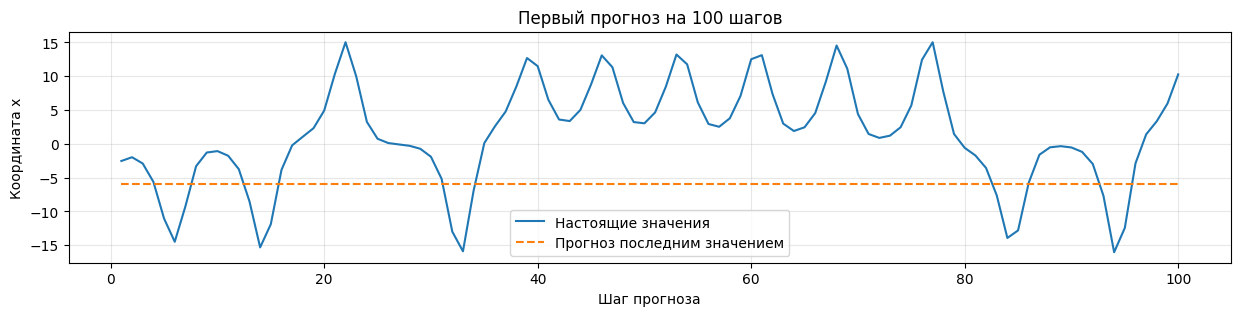

In [7]:
f_steps = np.arange(1, horizon + 1)

plt.figure(figsize=(15, 3))

plt.plot(f_steps, actual, label="Настоящие значения")
plt.plot(f_steps, prediction, linestyle="--", label="Прогноз последним значением")

plt.xlabel("Шаг прогноза")
plt.ylabel("Координата x")
plt.title("Первый прогноз на 100 шагов")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [8]:
errors = prediction - actual

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
nrmse = rmse / np.std(train)

print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | NRMSE: {nrmse:.3f}")

MAE: 8.974 | RMSE: 10.422 | NRMSE: 1.337


теперь из нескольких моментов старта оценим

In [9]:
horizon = 100
n_forecasts = len(val) - horizon + 1

all_predictions = np.empty((n_forecasts, horizon))
all_actual = np.empty((n_forecasts, horizon))

for start in range(n_forecasts):
    if start == 0:
        last_value = train[-1]
    else:
        last_value = val[start - 1]

    all_predictions[start] = np.full(horizon, last_value)
    all_actual[start] = val[start:start + horizon]

print("Форма массива прогнозов:", all_predictions.shape)

Форма массива прогнозов: (14451, 100)


In [10]:
errors = all_predictions - all_actual

mae_by_horizon = np.mean(np.abs(errors), axis=0)
rmse_by_horizon = np.sqrt(np.mean(errors ** 2, axis=0))
nrmse_by_horizon = rmse_by_horizon / np.std(train)

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | MAE: {mae_by_horizon[h - 1]:.3f} | RMSE: {rmse_by_horizon[h - 1]:.3f} | NRMSE: {nrmse_by_horizon[h - 1]:.3f}")

Горизонт: 1 | MAE: 3.258 | RMSE: 3.953 | NRMSE: 0.507
Горизонт: 5 | MAE: 7.972 | RMSE: 9.634 | NRMSE: 1.236
Горизонт: 10 | MAE: 8.074 | RMSE: 9.945 | NRMSE: 1.276
Горизонт: 20 | MAE: 8.532 | RMSE: 10.246 | NRMSE: 1.315
Горизонт: 50 | MAE: 9.022 | RMSE: 10.887 | NRMSE: 1.397
Горизонт: 100 | MAE: 9.137 | RMSE: 11.173 | NRMSE: 1.434


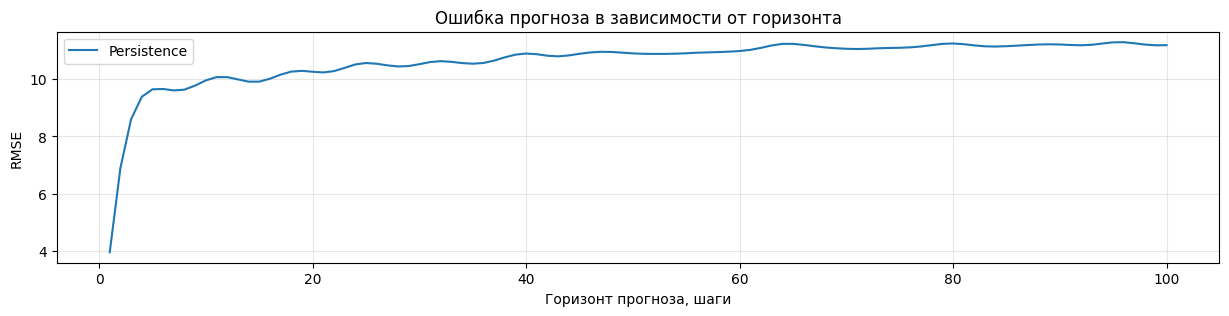

In [11]:
forecast_steps = np.arange(1, horizon + 1)

plt.figure(figsize=(15, 3))
plt.plot(forecast_steps, rmse_by_horizon, label="Persistence")

plt.xlabel("Горизонт прогноза, шаги")
plt.ylabel("RMSE")
plt.title("Ошибка прогноза в зависимости от горизонта")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Среднее ряда

In [12]:
train_mean = np.mean(train)

mean_errors = train_mean - all_actual

mae_mean = np.mean(np.abs(mean_errors), axis=0)
rmse_mean = np.sqrt(np.mean(mean_errors ** 2, axis=0))
nrmse_mean = rmse_mean / np.std(train)

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | RMSE последним значением: {rmse_by_horizon[h - 1]:.3f} | RMSE среднего: {rmse_mean[h - 1]:.3f}")

Горизонт: 1 | RMSE последним значением: 3.953 | RMSE среднего: 7.798
Горизонт: 5 | RMSE последним значением: 9.634 | RMSE среднего: 7.799
Горизонт: 10 | RMSE последним значением: 9.945 | RMSE среднего: 7.798
Горизонт: 20 | RMSE последним значением: 10.246 | RMSE среднего: 7.798
Горизонт: 50 | RMSE последним значением: 10.887 | RMSE среднего: 7.799
Горизонт: 100 | RMSE последним значением: 11.173 | RMSE среднего: 7.799


Очев лучше

## Линейная регрессия

###  Рекурсивно

Подготовка

In [13]:
lookback = 34 # перебором всех значений получила

train_mean = np.mean(train)
train_std = np.std(train)

train_scaled = (train - train_mean) / train_std

# Окна по 20 значений истории и одно следующее значение.
windows = np.lib.stride_tricks.sliding_window_view(train_scaled, lookback + 1)

X_train = windows[:, :lookback].copy()
y_train = windows[:, -1].copy()

Я решила и обычную, и Ridge

In [14]:
from sklearn.linear_model import LinearRegression, Ridge

linear_model = LinearRegression()
ridge_model = Ridge(alpha=0.63) # по лог сектке перебирала

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

print("Обучились")

Обучились


In [15]:
history = np.concatenate([train[-lookback:], val])
history_scaled = (history - train_mean) / train_std

val_windows = np.lib.stride_tricks.sliding_window_view(history_scaled, lookback + 1)

X_val_one = val_windows[:n_forecasts, :lookback].copy()
actual_one = all_actual[:, 0]

In [16]:
linear_prediction = linear_model.predict(X_val_one) * train_std + train_mean
ridge_prediction = ridge_model.predict(X_val_one) * train_std + train_mean

rmse_linear = np.sqrt(np.mean((linear_prediction - actual_one) ** 2))
rmse_ridge = np.sqrt(np.mean((ridge_prediction - actual_one) ** 2))

print(f"Последнее значение: RMSE = {rmse_by_horizon[0]:.3f}")
print(f"Среднее обучения: RMSE = {rmse_mean[0]:.3f}")
print(f"LinearRegression: RMSE = {rmse_linear:.3f}")
print(f"Ridge: RMSE = {rmse_ridge:.3f}")

Последнее значение: RMSE = 3.953
Среднее обучения: RMSE = 7.798
LinearRegression: RMSE = 2.306
Ridge: RMSE = 2.306


Все хорошо, теперь напишу рекурсию, чтобы следующее предсказывать по предыдущим

In [17]:
def recursive_f(model, histories, horizon):
    current_windows = histories.copy()
    predictions = np.empty((len(histories), horizon))

    for step in range(horizon):
        next_values = model.predict(current_windows)
        predictions[:, step] = next_values
        current_windows = np.column_stack([current_windows[:, 1:], next_values])

    return predictions

In [18]:
linear_forecasts = recursive_f(linear_model, X_val_one, horizon) * train_std + train_mean
ridge_forecasts = recursive_f(ridge_model, X_val_one, horizon) * train_std + train_mean

In [19]:
rmse_linear_by_horizon = np.sqrt(np.mean((linear_forecasts - all_actual) ** 2, axis=0))
rmse_ridge_by_horizon = np.sqrt(np.mean((ridge_forecasts - all_actual) ** 2, axis=0))

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | RMSE LinearRegression: {rmse_linear_by_horizon[h - 1]:.3f} | RMSE Ridge: {rmse_ridge_by_horizon[h - 1]:.3f}")

Горизонт: 1 | RMSE LinearRegression: 2.306 | RMSE Ridge: 2.306
Горизонт: 5 | RMSE LinearRegression: 7.373 | RMSE Ridge: 7.373
Горизонт: 10 | RMSE LinearRegression: 7.519 | RMSE Ridge: 7.519
Горизонт: 20 | RMSE LinearRegression: 7.686 | RMSE Ridge: 7.686
Горизонт: 50 | RMSE LinearRegression: 7.797 | RMSE Ridge: 7.797
Горизонт: 100 | RMSE LinearRegression: 7.800 | RMSE Ridge: 7.800


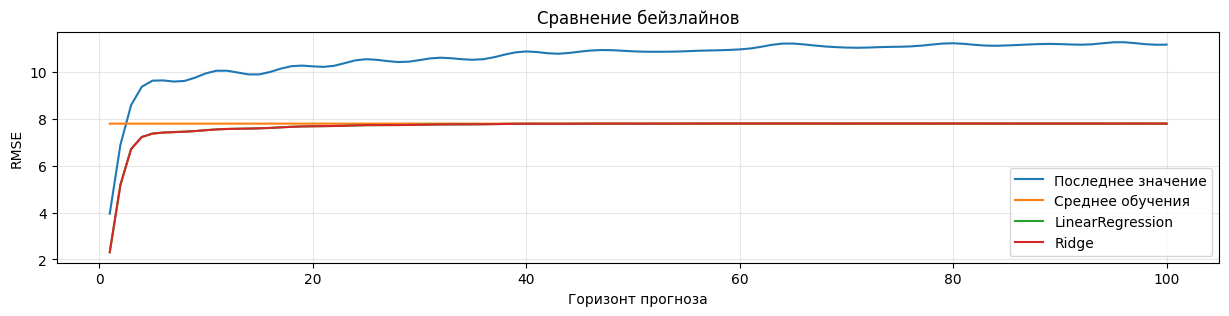

In [20]:
plt.figure(figsize=(15, 3))

plt.plot(forecast_steps, rmse_by_horizon, label="Последнее значение")
plt.plot(forecast_steps, rmse_mean, label="Среднее обучения")
plt.plot(forecast_steps, rmse_linear_by_horizon, label="LinearRegression")
plt.plot(forecast_steps, rmse_ridge_by_horizon, label="Ridge")

plt.xlabel("Горизонт прогноза")
plt.ylabel("RMSE")
plt.title("Сравнение бейзлайнов")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Прямой подход

In [21]:
direct_windows = np.lib.stride_tricks.sliding_window_view(train_scaled, lookback + horizon)

X_train_direct = direct_windows[:, :lookback].copy()
y_train_direct = direct_windows[:, lookback:].copy()

In [22]:
linear_direct_model = LinearRegression()
ridge_direct_model = Ridge(alpha=0.63)

linear_direct_model.fit(X_train_direct, y_train_direct)
ridge_direct_model.fit(X_train_direct, y_train_direct)

linear_direct_forecasts = linear_direct_model.predict(X_val_one) * train_std + train_mean
ridge_direct_forecasts = ridge_direct_model.predict(X_val_one) * train_std + train_mean

In [23]:
rmse_linear_direct = np.sqrt(np.mean((linear_direct_forecasts - all_actual) ** 2, axis=0))
rmse_ridge_direct = np.sqrt(np.mean((ridge_direct_forecasts - all_actual) ** 2, axis=0))

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | Linear рекурсивно: {rmse_linear_by_horizon[h - 1]:.3f} | Linear прямо: {rmse_linear_direct[h - 1]:.3f} |"
          f"Ridge рекурсивно: {rmse_ridge_by_horizon[h - 1]:.3f} | Ridge прямо: {rmse_ridge_direct[h - 1]:.3f}")

Горизонт: 1 | Linear рекурсивно: 2.306 | Linear прямо: 2.306 |Ridge рекурсивно: 2.306 | Ridge прямо: 2.307
Горизонт: 5 | Linear рекурсивно: 7.373 | Linear прямо: 7.376 |Ridge рекурсивно: 7.373 | Ridge прямо: 7.376
Горизонт: 10 | Linear рекурсивно: 7.519 | Linear прямо: 7.525 |Ridge рекурсивно: 7.519 | Ridge прямо: 7.525
Горизонт: 20 | Linear рекурсивно: 7.686 | Linear прямо: 7.695 |Ridge рекурсивно: 7.686 | Ridge прямо: 7.695
Горизонт: 50 | Linear рекурсивно: 7.797 | Linear прямо: 7.808 |Ridge рекурсивно: 7.797 | Ridge прямо: 7.808
Горизонт: 100 | Linear рекурсивно: 7.800 | Linear прямо: 7.811 |Ridge рекурсивно: 7.800 | Ridge прямо: 7.811


## KNN

### Прямой

In [24]:
lookback_knn = 4 # Перебрала от 1 до 100

In [25]:
knn_windows = np.lib.stride_tricks.sliding_window_view(train_scaled, lookback_knn + horizon)

X_train_knn = knn_windows[:, :lookback_knn].copy()
y_train_knn = knn_windows[:, lookback_knn:].copy()

In [26]:
from sklearn.neighbors import KNeighborsRegressor

history_knn = np.concatenate([train[-lookback_knn:], val])
history_knn_scaled = (history_knn - train_mean) / train_std
val_windows_knn = np.lib.stride_tricks.sliding_window_view(history_knn_scaled, lookback_knn + 1)

X_val_knn = val_windows_knn[:n_forecasts, :lookback_knn].copy()

knn_model = KNeighborsRegressor(n_neighbors=20, weights="distance", metric="minkowski", p=2, algorithm="kd_tree")
knn_model.fit(X_train_knn, y_train_knn)

knn_forecasts = knn_model.predict(X_val_knn) * train_std + train_mean

Метрики

In [27]:
knn_errors = knn_forecasts - all_actual

mae_knn = np.mean(np.abs(knn_errors), axis=0)
rmse_knn = np.sqrt(np.mean(knn_errors ** 2, axis=0))
nrmse_knn = rmse_knn / train_std

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | MAE: {mae_knn[h - 1]:.3f} | RMSE: {rmse_knn[h - 1]:.3f} | NRMSE: {nrmse_knn[h - 1]:.3f}")

Горизонт: 1 | MAE: 0.037 | RMSE: 0.069 | NRMSE: 0.009
Горизонт: 5 | MAE: 0.152 | RMSE: 0.399 | NRMSE: 0.051
Горизонт: 10 | MAE: 0.501 | RMSE: 1.725 | NRMSE: 0.221
Горизонт: 20 | MAE: 1.373 | RMSE: 2.731 | NRMSE: 0.350
Горизонт: 50 | MAE: 5.469 | RMSE: 7.225 | NRMSE: 0.927
Горизонт: 100 | MAE: 6.425 | RMSE: 8.036 | NRMSE: 1.031


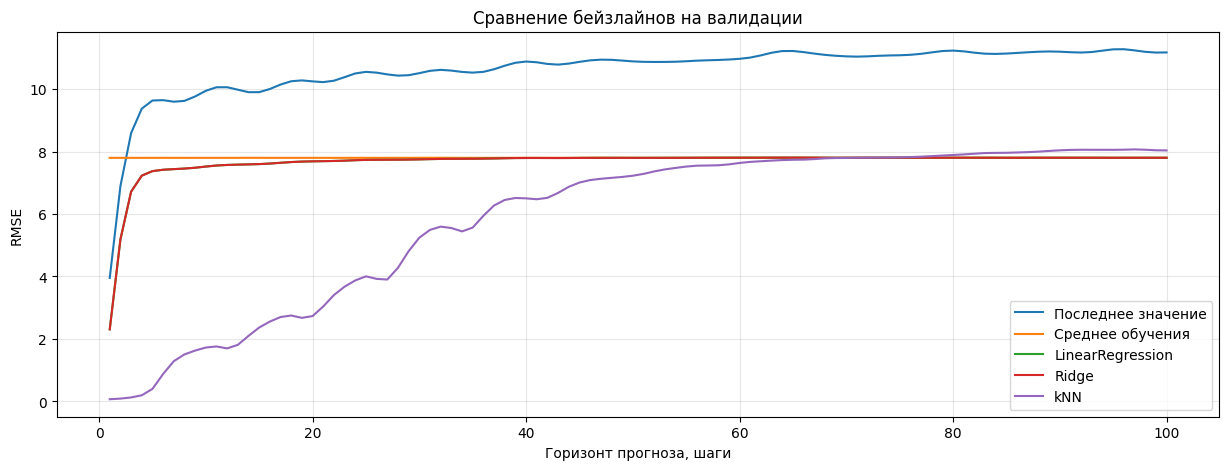

In [28]:
plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, rmse_by_horizon, label="Последнее значение")
plt.plot(forecast_steps, rmse_mean, label="Среднее обучения")
plt.plot(forecast_steps, rmse_linear_by_horizon, label="LinearRegression")
plt.plot(forecast_steps, rmse_ridge_by_horizon, label="Ridge")
plt.plot(forecast_steps, rmse_knn, label="kNN")

plt.xlabel("Горизонт прогноза, шаги")
plt.ylabel("RMSE")
plt.title("Сравнение бейзлайнов на валидации")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Рекурсивный

Теперь по 1 значению буду прогнозировать 

In [29]:
from threadpoolctl import threadpool_limits

knn_recursive_model = KNeighborsRegressor(n_neighbors=1, weights="uniform", metric="minkowski", p=1, algorithm="kd_tree") # Перебирала
knn_recursive_model.fit(X_train_knn, y_train_knn[:, 0])

with threadpool_limits(limits=1):
    knn_recursive_forecasts = recursive_f(knn_recursive_model, X_val_knn, horizon) * train_std + train_mean

Метрики

In [30]:
knn_recursive_errors = knn_recursive_forecasts - all_actual

mae_knn_recursive = np.mean(np.abs(knn_recursive_errors), axis=0)
rmse_knn_recursive = np.sqrt(np.mean(knn_recursive_errors ** 2, axis=0))
nrmse_knn_recursive = rmse_knn_recursive / train_std

for h in [1, 5, 10, 20, 50, 100]:
    print(f"Горизонт: {h} | RMSE kNN прямо: {rmse_knn[h - 1]:.3f} | RMSE kNN рекурсивно: {rmse_knn_recursive[h - 1]:.3f}")

Горизонт: 1 | RMSE kNN прямо: 0.069 | RMSE kNN рекурсивно: 0.074
Горизонт: 5 | RMSE kNN прямо: 0.399 | RMSE kNN рекурсивно: 0.463
Горизонт: 10 | RMSE kNN прямо: 1.725 | RMSE kNN рекурсивно: 1.788
Горизонт: 20 | RMSE kNN прямо: 2.731 | RMSE kNN рекурсивно: 2.933
Горизонт: 50 | RMSE kNN прямо: 7.225 | RMSE kNN рекурсивно: 8.930
Горизонт: 100 | RMSE kNN прямо: 8.036 | RMSE kNN рекурсивно: 10.850


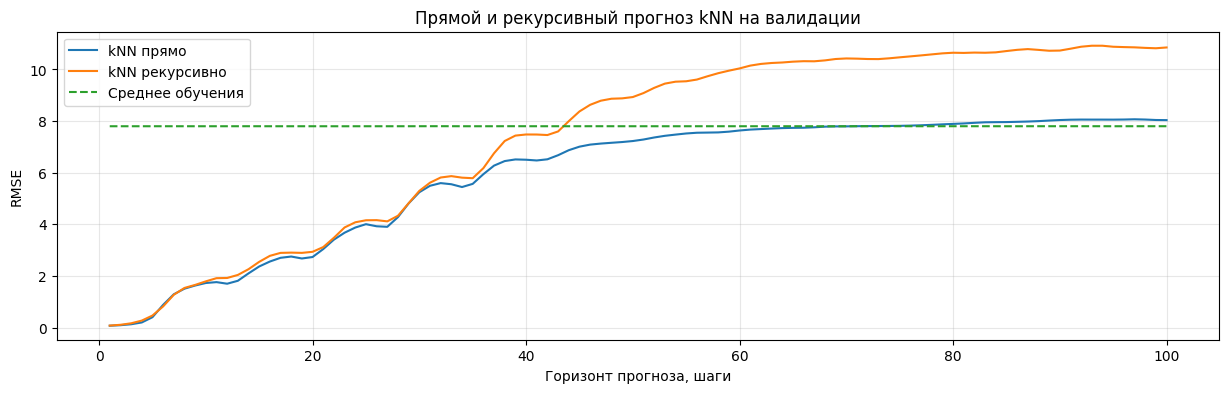

In [31]:
plt.figure(figsize=(15, 4))

plt.plot(forecast_steps, rmse_knn, label="kNN прямо")
plt.plot(forecast_steps, rmse_knn_recursive, label="kNN рекурсивно")
plt.plot(forecast_steps, rmse_mean, linestyle="--", label="Среднее обучения")

plt.xlabel("Горизонт прогноза, шаги")
plt.ylabel("RMSE")
plt.title("Прямой и рекурсивный прогноз kNN на валидации")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Проверка бейзлайнов на тесте

In [32]:
n_test_forecasts = len(test) - horizon + 1
actual_test = np.lib.stride_tricks.sliding_window_view(test, horizon).copy()

history_test = np.concatenate([val[-lookback:], test])
history_test_scaled = (history_test - train_mean) / train_std
windows_test = np.lib.stride_tricks.sliding_window_view(history_test_scaled, lookback + 1)

X_test_linear = windows_test[:n_test_forecasts, :lookback].copy()

history_test_knn = np.concatenate([val[-lookback_knn:], test])
history_test_knn_scaled = (history_test_knn - train_mean) / train_std
windows_test_knn = np.lib.stride_tricks.sliding_window_view(history_test_knn_scaled, lookback_knn + 1)

X_test_knn = windows_test_knn[:n_test_forecasts, :lookback_knn].copy()

print(f"Linear/Ridge: {X_test_linear.shape} | kNN: {X_test_knn.shape} | Цели: {actual_test.shape}")

Linear/Ridge: (14452, 34) | kNN: (14452, 4) | Цели: (14452, 100)


Прогнозы

In [ ]:
with threadpool_limits(limits=1):
    test_forecasts = {
        "Последнее значение": np.repeat(X_test_linear[:, -1:], horizon, axis=1) * train_std + train_mean,
        "Среднее обучения": np.full_like(actual_test, train_mean),
        "Linear рекурсивно": recursive_f(linear_model, X_test_linear, horizon) * train_std + train_mean,
        "Linear прямо": linear_direct_model.predict(X_test_linear) * train_std + train_mean,
        "Ridge рекурсивно": recursive_f(ridge_model, X_test_linear, horizon) * train_std + train_mean,
        "Ridge прямо": ridge_direct_model.predict(X_test_linear) * train_std + train_mean,
        "kNN рекурсивно": recursive_f(knn_recursive_model, X_test_knn, horizon) * train_std + train_mean,
        "kNN прямо": knn_model.predict(X_test_knn) * train_std + train_mean,
    }

Метрики

In [39]:
import pandas as pd

test_mae = {}
test_rmse = {}
test_nrmse = {}
summary_rows = []

for name, predictions in test_forecasts.items():
    errors = predictions - actual_test

    test_mae[name] = np.mean(np.abs(errors), axis=0)
    test_rmse[name] = np.sqrt(np.mean(errors ** 2, axis=0))
    test_nrmse[name] = test_rmse[name] / train_std

    row = {"Модель": name}

    for h in [1, 5, 10, 20, 50, 100]:
        row[f"h={h}"] = test_rmse[name][h - 1]

    summary_rows.append(row)

test_summary = pd.DataFrame(summary_rows).set_index("Модель")
test_summary.sort_values("h=1").round(3)

,h=1,h=5,h=10,h=20,h=50,h=100
Модель,,,,,,
kNN прямо,0.072,0.392,1.615,2.629,7.069,8.040
kNN рекурсивно,0.073,0.467,1.749,2.849,8.811,10.870
Linear прямо,2.302,7.379,7.517,7.645,7.774,7.800
Linear рекурсивно,2.302,7.381,7.523,7.653,7.781,7.799
Ridge прямо,2.302,7.379,7.517,7.645,7.774,7.800
Ridge рекурсивно,2.302,7.381,7.523,7.653,7.781,7.799
Последнее значение,3.947,9.638,9.949,10.226,10.675,10.933
Среднее обучения,7.801,7.799,7.800,7.799,7.799,7.800


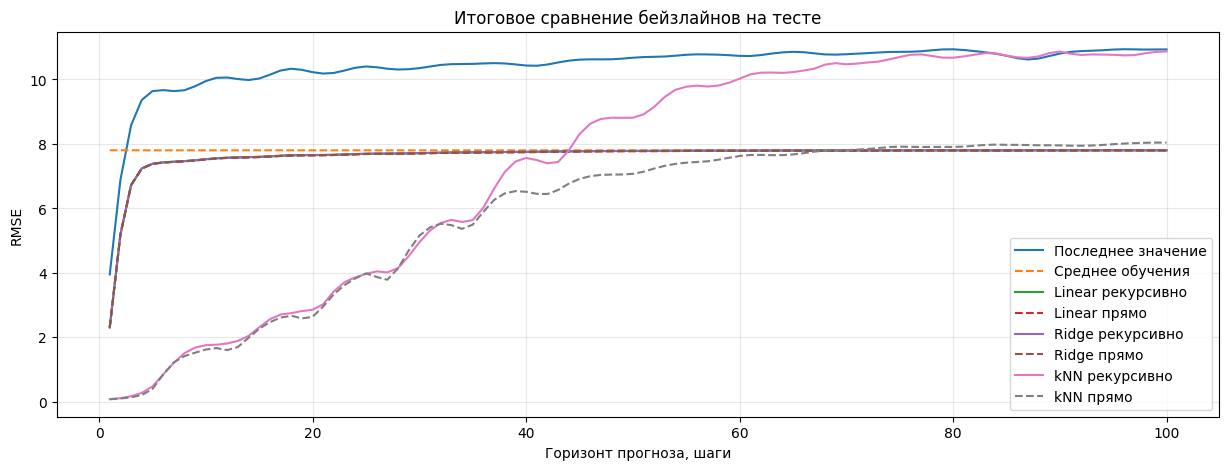

In [43]:
plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, test_rmse["Последнее значение"], label="Последнее значение")
plt.plot(forecast_steps, test_rmse["Среднее обучения"], linestyle="--", label="Среднее обучения")
plt.plot(forecast_steps, test_rmse["Linear рекурсивно"], label="Linear рекурсивно")
plt.plot(forecast_steps, test_rmse["Linear прямо"], linestyle="--", label="Linear прямо")
plt.plot(forecast_steps, test_rmse["Ridge рекурсивно"], label="Ridge рекурсивно")
plt.plot(forecast_steps, test_rmse["Ridge прямо"], linestyle="--", label="Ridge прямо")
plt.plot(forecast_steps, test_rmse["kNN рекурсивно"], label="kNN рекурсивно")
plt.plot(forecast_steps, test_rmse["kNN прямо"], linestyle="--", label="kNN прямо")

plt.xlabel("Горизонт прогноза, шаги")
plt.ylabel("RMSE")
plt.title("Итоговое сравнение бейзлайнов на тесте")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Графики разных примеров

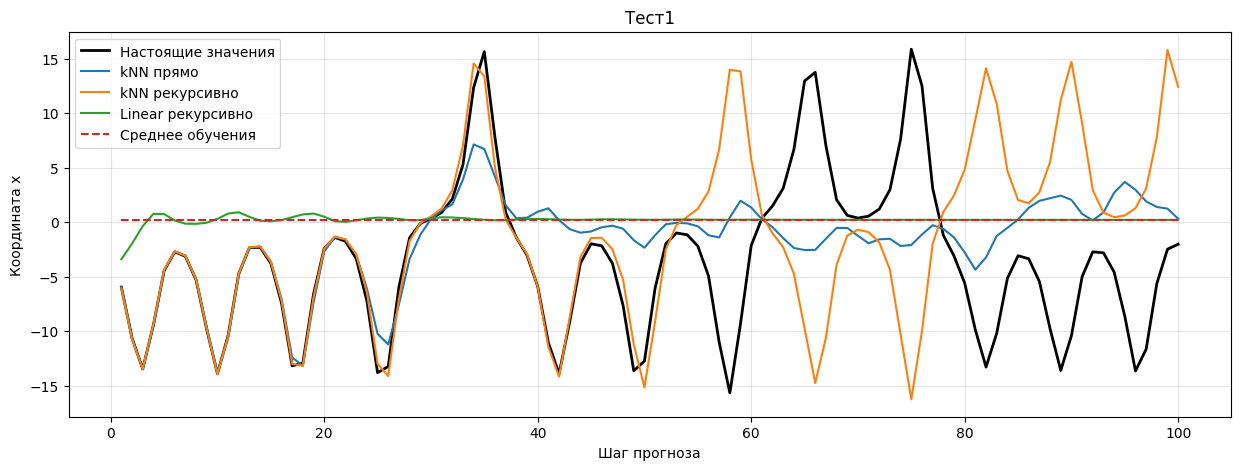

In [70]:
example = 0

plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, actual_test[example], color="black", linewidth=2, label="Настоящие значения")
plt.plot(forecast_steps, test_forecasts["kNN прямо"][example], label="kNN прямо")
plt.plot(forecast_steps, test_forecasts["kNN рекурсивно"][example], label="kNN рекурсивно")
plt.plot(forecast_steps, test_forecasts["Linear рекурсивно"][example], label="Linear рекурсивно")
plt.plot(forecast_steps, test_forecasts["Среднее обучения"][example], linestyle="--", label="Среднее обучения")

plt.xlabel("Шаг прогноза")
plt.ylabel("Координата x")
plt.title(f"Тест{example + 1}")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [71]:
example_errors = test_forecasts["kNN рекурсивно"][example] - actual_test[example]

print(f"RMSE первых 40 шагов этого примера: {np.sqrt(np.mean(example_errors[:40] ** 2)):.3f}")
print(f"Ошибка этого примера на шаге 40: {abs(example_errors[39]):.3f}")
print(f"RMSE по всем стартам на шаге 40: {test_rmse['kNN рекурсивно'][39]:.3f}")

RMSE первых 40 шагов этого примера: 0.801
Ошибка этого примера на шаге 40: 0.024
RMSE по всем стартам на шаге 40: 7.562


-------------------------------------------------------------

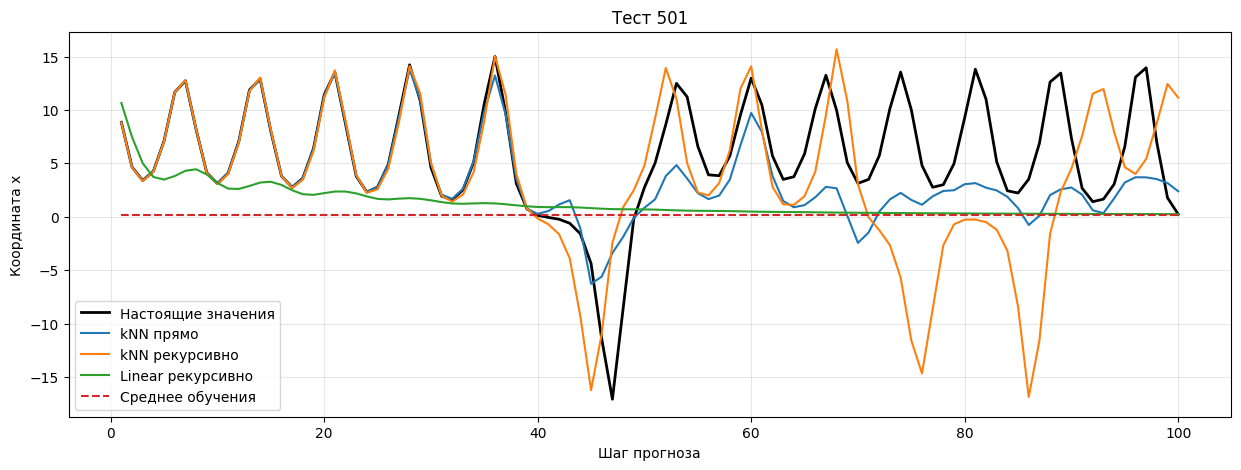

In [80]:
example = 500

plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, actual_test[example], color="black", linewidth=2, label="Настоящие значения")
plt.plot(forecast_steps, test_forecasts["kNN прямо"][example], label="kNN прямо")
plt.plot(forecast_steps, test_forecasts["kNN рекурсивно"][example], label="kNN рекурсивно")
plt.plot(forecast_steps, test_forecasts["Linear рекурсивно"][example], label="Linear рекурсивно")
plt.plot(forecast_steps, test_forecasts["Среднее обучения"][example], linestyle="--", label="Среднее обучения")

plt.xlabel("Шаг прогноза")
plt.ylabel("Координата x")
plt.title(f"Тест {example + 1}")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

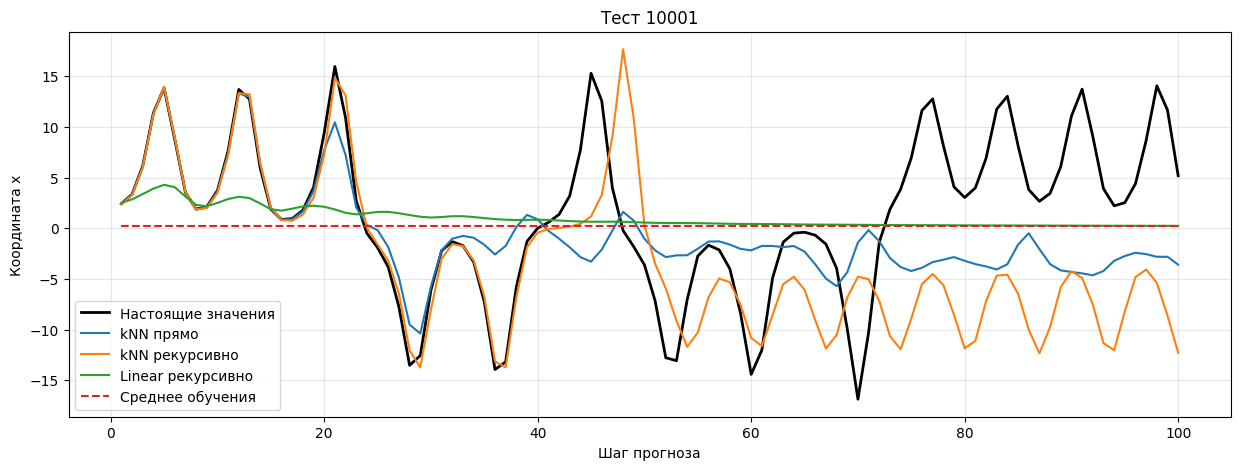

In [82]:
example = 10000

plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, actual_test[example], color="black", linewidth=2, label="Настоящие значения")
plt.plot(forecast_steps, test_forecasts["kNN прямо"][example], label="kNN прямо")
plt.plot(forecast_steps, test_forecasts["kNN рекурсивно"][example], label="kNN рекурсивно")
plt.plot(forecast_steps, test_forecasts["Linear рекурсивно"][example], label="Linear рекурсивно")
plt.plot(forecast_steps, test_forecasts["Среднее обучения"][example], linestyle="--", label="Среднее обучения")

plt.xlabel("Шаг прогноза")
plt.ylabel("Координата x")
plt.title(f"Тест {example + 1}")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

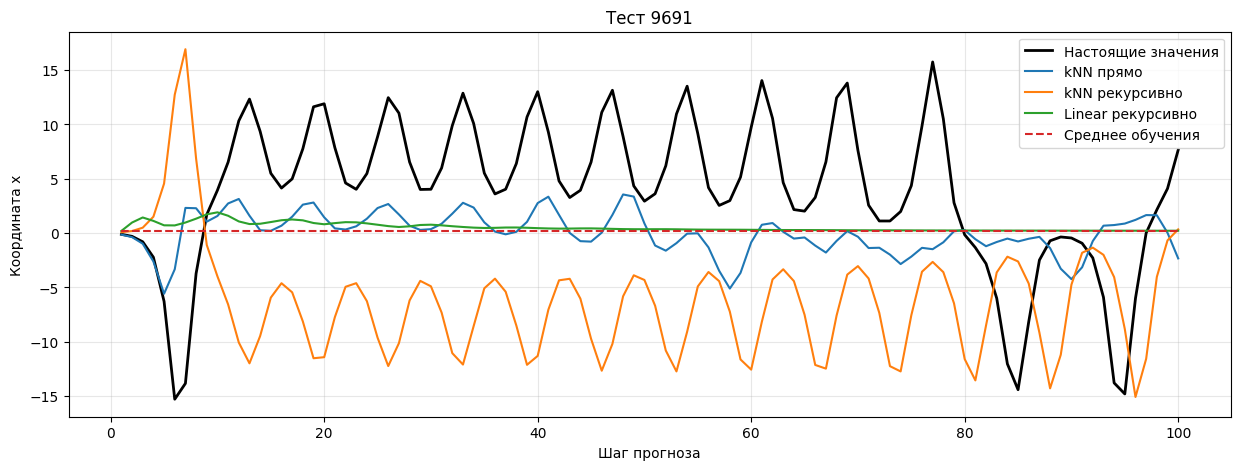

In [83]:
example = 9690

plt.figure(figsize=(15, 5))

plt.plot(forecast_steps, actual_test[example], color="black", linewidth=2, label="Настоящие значения")
plt.plot(forecast_steps, test_forecasts["kNN прямо"][example], label="kNN прямо")
plt.plot(forecast_steps, test_forecasts["kNN рекурсивно"][example], label="kNN рекурсивно")
plt.plot(forecast_steps, test_forecasts["Linear рекурсивно"][example], label="Linear рекурсивно")
plt.plot(forecast_steps, test_forecasts["Среднее обучения"][example], linestyle="--", label="Среднее обучения")

plt.xlabel("Шаг прогноза")
plt.ylabel("Координата x")
plt.title(f"Тест {example + 1}")
plt.legend()
plt.grid(alpha=0.3)

plt.show()